# Сравнение моделей для детекции бабочек

Порядок написания кода для проекта:

| Порядок | Какие функции подключаем | Зачем |
|---|---|---|
| 1. Формат данных | `read_manifest`, `read_jsonl`, `write_jsonl` | Читаем фото и эталон и связываем их по `photo_id`. |
| 2. Рамки | `normalized_box`, `parse_qwen`, `check_boxes` | Приводим ответы трёх моделей к одной геометрии. |
| 3. Конфиги и пороги | `Config`, `select_boxes` | Настраиваем модель и фильтруем кандидатов. |
| 4. Метрики | `iou_matrix`, `evaluate`, `summarize` | Сопоставляем рамки и считаем метрики по датасету. |
| 5. Сохранение | `export_predictions`, `validate_submission` | Проверяем формат экспорта и различаем отсутствие объектов и сбой. |
| 6. Реальные фотографии | `open_image`, `choose_device`, `load_detector`, `predict_one`, `run_model` | Проверяем по одному фото, затем запускаем весь датасет. |
| 7–9. Результаты | `make_leaderboard`, подбор порога, просмотр FP/FN | Сохраняем базовый лидерборд, проводим эксперимент и сравниваем варианты. |
| 10. Контест | `read_contest_manifest`, `read_settings`, `validate_submission` | Используем настройки победителя и проверяем посылку. |

В каждом разделе сначала идёт **небольшая проверка**, следом — **применение к данным проекта**. Чтение файлов, инференс, вычисление метрик и экспорт реализованы в `models/`.


Историческая версия. Выводы сохранены от первоначального прогона. Для нового запуска используйте [актуальное сравнение бейзлайнов](../baseline/models_comparison.ipynb).

In [1]:
import json
from math import isclose
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib.patches import Rectangle

import sys
from pathlib import Path
from IPython.display import display

cwd = Path.cwd().resolve()
candidates = (cwd, *cwd.parents, Path("/kaggle/working/data-labeling-shad"))
ROOT = next((p for p in candidates if (p / "model_comparison/workflow.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Открой ноутбук из клона репозитория или склонируй его в /kaggle/working/data-labeling-shad")
sys.path.insert(0, str(ROOT))
print("Корень репозитория найден")

from model_comparison.models.configs import CONFIGS, OWL_EXPERIMENT_THRESHOLDS, Config
from model_comparison.models.detectors import choose_device, normalized_box, parse_qwen, select_boxes
from model_comparison.models.metrics import evaluate, iou_matrix
from model_comparison.models.pipeline import (
    check_boxes, export_predictions, open_image, read_contest_manifest, read_jsonl,
    read_manifest, read_settings, run_model, validate_submission, write_jsonl,
)

DATA = ROOT / "data"
SAVED_RESULTS = ROOT / "model_comparison/results"
RESULTS = ROOT / "runs/archived_baseline"

In [2]:
import sys
print(sys.executable)

/home/daryas/data-labeling-shad/.venv/bin/python


## 1. Чтение данных

`read_manifest` читает фотографии из JSON, а `read_jsonl` читает по одной записи с рамками на строку. Обе функции возвращают словари с ключом `photo_id`. Поэтому порядок записей может различаться.

In [3]:
team = read_manifest(DATA / "val_dataset.json")
golden = read_jsonl(DATA / "golden.jsonl")
missing = set(team) - set(golden)
extra = set(golden) - set(team)
if missing or extra:
    raise ValueError(f"В эталоне пропущено {len(missing)} ID, лишних {len(extra)} ID")

dataset_table = pd.DataFrame([
    {"photo_id": photo_id, "group": row["group"], "n_boxes": len(golden[photo_id]["boxes"])}
    for photo_id, row in team.items()
])
print(f"Совпали ID для {len(team)} фото.")

display(dataset_table.groupby("group").agg(
    photos=("photo_id", "size"),
    photos_with_boxes=("n_boxes", lambda counts: counts.gt(0).sum()),
    boxes=("n_boxes", "sum")
))

Совпали ID для 400 фото.


,photos,photos_with_boxes,boxes
group,,,
butterfly,191,191,191
insect,101,0,0
multiple_butterfly,6,6,27
no_butterfly,102,0,0


## 2. Проверяем формат рамок

`normalized_box` переводит два угла в `left, top, width, height` в долях кадра. `parse_qwen` делает то же с углами из ответа Qwen, где шкала 0–1000. `check_boxes` проверяет границы и размеры рамок.

На прямоугольном кадре вручную рассчитываем ожидаемые доли. Проверяем, что ответ Qwen даёт ту же рамку, а у вырожденной рамки возвращается `None`.

In [4]:
# Кадр 200×100 помогает заметить перепутанные оси.
box = normalized_box([20, 20, 80, 60], width=200, height=100)
expected = {"left": 0.10, "top": 0.20, "width": 0.30, "height": 0.40}
assert all(isclose(box[key], value) for key, value in expected.items())
assert normalized_box([20, 20, 20, 60], width=200, height=100) is None

qwen_box, = parse_qwen('[{"bbox_2d": [100, 200, 400, 600]}]')
assert all(isclose(qwen_box[key], box[key]) for key in box)
assert parse_qwen("[]") == []
try:
    parse_qwen('{"unexpected": "wrong format"}')
except ValueError:
    pass
else:
    raise AssertionError("Некорректный ответ Qwen принят")
check_boxes([box, qwen_box])
print("ОК. Пиксели и ответы Qwen приводятся к одному формату.")

ОК. Пиксели и ответы Qwen приводятся к одному формату.


Эталон уже хранится в долях кадра. Проверяем все его рамки и выводим один настоящий пример.

In [5]:
for photo_id, row in golden.items():
    if row.get("error") is not None:
        raise ValueError(f"Неразобранное фото в эталоне: {photo_id}")
    check_boxes(row["boxes"])

real_example_id = next(photo_id for photo_id, row in golden.items() if row["boxes"])
print(f"Проверено {dataset_table['n_boxes'].sum()} рамок.")
display(pd.DataFrame(golden[real_example_id]["boxes"]).assign(photo_id=real_example_id))

Проверено 218 рамок.


,left,top,width,height,photo_id
0,0.14572,0.182418,0.599271,0.626374,760590036


## 3. Проверяем IoU и оценку детекции

`iou_matrix` считает долю пересечения от объединения. `evaluate` сопоставляет рамки отдельно при IoU 0.50 и 0.75. Одна рамка может войти только в одну пару. По общим числам совпадений, лишних рамок и пропусков считаются precision, recall и F1.

**Проверка.** Одна рамка с IoU 0.60 засчитывается при пороге 0.50. При 0.75 она даёт одну лишнюю рамку и один пропуск. Лишняя рамка на кадре без бабочек даёт FP при обоих порогах.

In [5]:
whole = {"left": 0.0, "top": 0.0, "width": 0.5, "height": 0.5}
part = {**whole, "width": 0.3}
far = {**whole, "left": 0.6, "width": 0.3}
assert isclose(iou_matrix([whole], [whole])[0, 0], 1.0)
assert isclose(iou_matrix([whole], [part])[0, 0], 0.6)
assert iou_matrix([whole], [far])[0, 0] == 0.0

# Здесь одна рамка с IoU 0.6 и одно ложное срабатывание на пустом фото.
example_gold = {101: {"boxes": [whole]}, 102: {"boxes": []}}
example_pred = {101: {"boxes": [part]}, 102: {"boxes": [far]}}
scores, photo_rows = evaluate([101, 102], example_gold, example_pred)
assert (scores["tp_50"], scores["fp_50"], scores["fn_50"]) == (1, 1, 0)
assert (scores["tp_75"], scores["fp_75"], scores["fn_75"]) == (0, 2, 1)
assert isclose(scores["f1_50"], 2 / 3)
assert scores["negative_photos_with_fp"] == 1

# Две одинаковые предсказанные рамки. Только одна засчитывается как TP.
duplicates, _ = evaluate([101], example_gold, {101: {"boxes": [whole, whole]}})
assert (duplicates["tp_50"], duplicates["fp_50"]) == (1, 1)
display(pd.DataFrame(photo_rows))
print("ОК. IoU, пороги сопоставления и обработка дубликатов проверены.")

,photo_id,is_negative,error,tp_50,fp_50,fn_50,tp_75,fp_75,fn_75
0,101,False,None,1,0,0,0,1,1
1,102,True,None,0,1,0,0,1,0


ОК. IoU, пороги сопоставления и обработка дубликатов проверены.


**На данных проекта.** Перед дорогим прогоном подаём настоящий эталон как предсказание. Ожидаем F1 = 1 и отсутствие лишних рамок и пропусков. Это проверка кода оценки; качество моделей появится после инференса.

In [6]:
sanity, _ = evaluate(team, golden, golden)
assert sanity["f1_50"] == sanity["f1_75"] == 1.0
assert sanity["fp_50"] == sanity["fn_50"] == 0
print(f"Самопроверка на реальном эталоне: {sanity['tp_50']} TP, F1@0.50 = {sanity['f1_50']:.1f}")

Самопроверка на реальном эталоне: 218 TP, F1@0.50 = 1.0


## 4. Запускаем модели

Настройки трёх моделей лежат в `models/configs.py`. `run_model` загружает веса, запускает инференс и сохраняет сырые предсказания. Повторный запуск использует кеш для уже обработанных кадров.

**Проверка на одном реальном фото.** Сначала запусти Grounding DINO. Для проверки OWLv2 и Qwen поменяй `PREVIEW_MODEL` и повтори ячейку. Зелёные рамки — эталон, оранжевые — предсказания модели. Первое выполнение скачает веса.

In [22]:
from dataclasses import replace
from time import perf_counter

from huggingface_hub import model_info
from model_comparison.models.detectors import load_detector, predict_one

config = CONFIGS["grounding_dino"]
device = choose_device()

print("1. Открываю фото", flush=True)
image = open_image(team[real_example_id]["image"])

print("2. Запрашиваю ревизию на Hugging Face", flush=True)
revision = model_info(config.model_id, timeout=20).sha
config = replace(config, revision=revision)

print(f"3. Загружаю веса на {device}", flush=True)
detector = load_detector(config, device)

print("4. Считаю предсказание", flush=True)
start = perf_counter()
candidates, _ = predict_one(detector, config, image, device)
print(f"Готово за {perf_counter() - start:.1f} с, рамок: {len(candidates)}")

1. Открываю фото
2. Запрашиваю ревизию на Hugging Face
3. Загружаю веса на cpu


Loading weights: 100%|██████████| 978/978 [00:02<00:00, 452.65it/s]


4. Считаю предсказание
Готово за 28.8 с, рамок: 4


In [23]:
from dataclasses import replace
from time import perf_counter

from huggingface_hub import model_info
from model_comparison.models.detectors import load_detector, predict_one

config = CONFIGS["owlv2"]
device = choose_device()

print("1. Открываю фото", flush=True)
image = open_image(team[real_example_id]["image"])

print("2. Запрашиваю ревизию на Hugging Face", flush=True)
revision = model_info(config.model_id, timeout=20).sha
config = replace(config, revision=revision)

print(f"3. Загружаю веса на {device}", flush=True)
detector = load_detector(config, device)

print("4. Считаю предсказание", flush=True)
start = perf_counter()
candidates, _ = predict_one(detector, config, image, device)
print(f"Готово за {perf_counter() - start:.1f} с, рамок: {len(candidates)}")

1. Открываю фото
2. Запрашиваю ревизию на Hugging Face
3. Загружаю веса на cpu


Loading weights: 100%|██████████| 418/418 [00:00<00:00, 780.54it/s]


4. Считаю предсказание
Готово за 18.0 с, рамок: 1


/home/daryas/data-labeling-shad/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


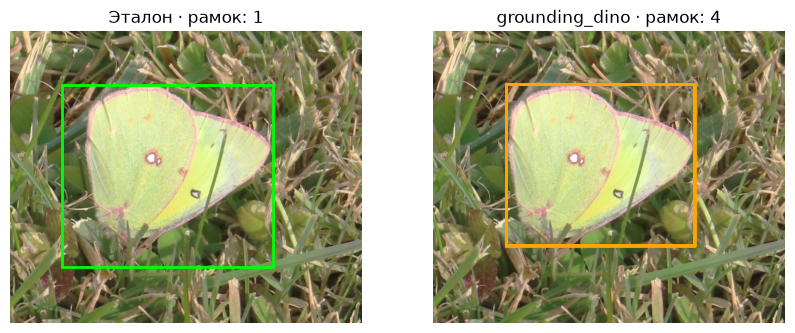

In [7]:
device = choose_device()
PREVIEW_MODEL = "grounding_dino"
PREVIEW_PHOTO_ID = real_example_id
config = CONFIGS[PREVIEW_MODEL]

preview_path = RESULTS / "preview" / f"{PREVIEW_MODEL}_{PREVIEW_PHOTO_ID}.jsonl"
preview = run_model(config, {PREVIEW_PHOTO_ID: team[PREVIEW_PHOTO_ID]}, preview_path, device)
record = preview[PREVIEW_PHOTO_ID]
if record["error"]:
    print("Сырой ответ:", record.get("raw_response"))
    raise RuntimeError(f"{record['error']} | подробности в {preview_path}")

image = open_image(team[PREVIEW_PHOTO_ID]["image"])
predicted_boxes = select_boxes(record["candidates"], config.threshold)
check_boxes(predicted_boxes)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, title, color, rectangles in (
    (axes[0], "Эталон", "lime", golden[PREVIEW_PHOTO_ID]["boxes"]),
    (axes[1], PREVIEW_MODEL, "orange", predicted_boxes),
):
    ax.imshow(image)
    for box in rectangles:
        ax.add_patch(Rectangle(
            (box["left"] * image.width, box["top"] * image.height),
            box["width"] * image.width, box["height"] * image.height,
            fill=False, edgecolor=color, linewidth=2,
        ))
    ax.set_title(f"{title} · рамок: {len(rectangles)}")
    ax.axis("off")
plt.show()

**На данных проекта.** После проверки запускаем три модели на всём наборе. Здесь сохраняются сырые ответы с уверенностью, временем и возможными сбоями.

In [ ]:
raw_by_model = {}
for name, config in CONFIGS.items():
    raw = run_model(config, team, RESULTS / "raw" / f"{name}.jsonl", device)
    assert set(raw) == set(team), f"У {name} неполный набор ID"
    raw_by_model[name] = raw
    failures = sum(bool(row["error"]) for row in raw.values())
    print(f"{name} | фото: {len(raw)} | сбоев: {failures}")

In [ ]:
name = 'grounding_dino'
config = CONFIGS[name]
raw = run_model(config, team, RESULTS / "raw" / f"{name}.jsonl", device)
assert set(raw) == set(team), f"У {name} неполный набор ID"
raw_by_model[name] = raw
failures = sum(bool(row["error"]) for row in raw.values())
print(f"{name} | фото: {len(raw)} | сбоев: {failures}")

## 5. Сохраняем предсказания и базовый лидерборд

In [9]:
from pathlib import Path
import pandas as pd

output = SAVED_RESULTS / "tables/leaderboard_baseline.csv"
baseline = pd.read_csv(output)

display(baseline[[
    "run", "f1_50", "f1_75", "precision_50", "recall_50",
    "negative_photos_with_fp", "technical_errors",
]].round(4))

print(f"Источник: {output}")

,run,f1_50,f1_75,precision_50,recall_50,negative_photos_with_fp,technical_errors
0,qwen,0.6508,0.5841,0.4976,0.9404,202,0
1,owlv2,0.4760,0.3486,0.3146,0.9771,103,0
2,grounding_dino,0.3788,0.3510,0.2375,0.9358,182,0


Сохранено: results/leaderboard_baseline.csv


In [11]:
import json
from pathlib import Path

val_path = DATA / "val_dataset.json"
golden_path = DATA / "golden.jsonl"
dino_path = SAVED_RESULTS / "predictions/grounding_dino.jsonl"

# JSON содержит список фотографий. В JSONL каждая строка — отдельная запись.
def read_jsonl(path):
    with path.open(encoding="utf-8-sig") as file:
        return [json.loads(line) for line in file if line.strip()]

def index_by_photo_id(rows, path):
    indexed = {}
    for row in rows:
        photo_id = row["photo_id"]
        if photo_id in indexed:
            raise ValueError(f"{path}: повторяется photo_id {photo_id}")
        indexed[photo_id] = row
    return indexed

photos = index_by_photo_id(
    json.loads(val_path.read_text(encoding="utf-8-sig")), val_path
)
golden = index_by_photo_id(read_jsonl(golden_path), golden_path)
dino = index_by_photo_id(read_jsonl(dino_path), dino_path)

for path, records in [(golden_path, golden), (dino_path, dino)]:
    missing = photos.keys() - records.keys()
    extra = records.keys() - photos.keys()
    if missing or extra:
        raise ValueError(
            f"{path}: пропущено {len(missing)} фото, лишних {len(extra)}"
        )

# Соединяем по photo_id, чтобы порядок строк в файлах не влиял на результат.
combined = [
    {
        "photo_id": photo_id,
        "url": photo["url"],
        "group": photo["group"],
        "boxes": golden[photo_id]["boxes"],
        "grounding_dino": {
            "boxes": dino[photo_id]["boxes"],
            "error": dino[photo_id]["error"],
        },
    }
    for photo_id, photo in photos.items()
]

output_path = RESULTS / "butterfly_validation.json"
output_path.parent.mkdir(parents=True, exist_ok=True)
output_path.write_text(
    json.dumps(combined, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)
print(f"Сохранено {len(combined)} фото в {output_path.resolve()}")

Сохранено 400 фото в /home/daryas/data-labeling-shad/butterfly_validation.json
